In [97]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
import seaborn as sns
import math
from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit
#from pomegranate import *
from sklearn.metrics import mean_squared_error
from sklearn.mixture import GaussianMixture
from scipy.stats import norm
from sklearn.neighbors import KernelDensity

In [77]:
def aic(y, y_pred, p):
    """
    Return an AIC score for a model.
    Input:
    y: array-like of shape = (n_samples) including values of observed y
    y_pred: vector including values of predicted y
    p: int number of predictive variable(s) used in the model
    Output:
    aic_score: int or float AIC score of the model
    Raise TypeError if y or y_pred are not list/tuple/dataframe column/array.
    Raise TypeError if elements in y or y_pred are not integer or float.
    Raise TypeError if p is not int.
    Raise InputError if y or y_pred are not in same length.
    Raise InputError if length(y) <= 1 or length(y_pred) <= 1.
    Raise InputError if p < 0.
    """

    # Package dependencies
    import numpy as np
    import pandas as pd

    # User-defined exceptions
    class InputError(Exception):
        """
        Raised when there is any error from inputs that no base Python exceptions cover.
        """
        pass

    # Check conditions:
    ## Type condition 1: y and y_pred should be array-like containing numbers
    ### check type of y and y_pred
    if isinstance(y, (np.ndarray, list, tuple, pd.core.series.Series)) == False or isinstance(y_pred, (np.ndarray, list, tuple, pd.core.series.Series)) == False:
        raise TypeError("Expect array-like shape (e.g. array, list, tuple, data column)")
    ### check if elements of y and y_pred are numeric
    else:
        for i in y:
            for j in y_pred:
                if isinstance(i, (int, float)) != True or isinstance(j, (int, float)) != True:
                    raise TypeError("Expect numeric elements in y and y_pred")

    ## Type condition 2: p should be positive integer
    ### check if p is integer
    if isinstance(p, int) != True:
        raise TypeError("Expect positive integer")
    ### check if p is positive
    elif p <= 0:
        raise InputError("Expect positive integer")

    ## Length condition: length of y and y_pred should be equal, and should be more than 1
    ### check if y and y_pred have equal length
    if not len(y) == len(y_pred):
        raise InputError("Expect equal length of y and y_pred")
    ### check if y and y_pred length is larger than 1
    elif len(y) <= 1 or len(y_pred) <= 1:
        raise InputError("Expect length of y and y_pred to be larger than 1")
    else:
        n = len(y)

    # Calculation
    resid = np.subtract(y_pred, y)
    rss = np.sum(np.power(resid, 2))
    #aic_score = n*np.log(rss/n) + 2*p
    aic_score = 2*np.log(rss) + 2*p

    return aic_score

In [74]:
def bic(y, y_pred, p):
    """
    Returns the BIC score of a model.
    Input:-
    y: the labelled data in shape of an array of size  = number of samples. 
        type = vector/array/list
    y_pred: predicted values of y from a regression model in shape of an array
        type = vector/array/list
    p: number of variables used for prediction in the model.
        type = int
    Output:-
    score: It outputs the BIC score
        type = int
    Tests:-
    Raise Error if length(y) <= 1 or length(y_pred) <= 1.
    Raise Error if length(y) != length(y_pred).
    Raise TypeError if y and y_pred are not vector.
    Raise TypeError if elements of y or y_pred are not integers.
    Raise TypeError if p is not an int.
    Raise Error if p < 0.
    """

    # package dependencies
    import numpy as np
    import pandas as pd
    import collections

    # Input type error exceptions
    if not isinstance(y, (collections.Sequence, np.ndarray, pd.core.series.Series)):
        raise TypeError("Argument 1 not like an array.")

    if not isinstance(y_pred, (collections.Sequence, np.ndarray, pd.core.series.Series)):
        raise TypeError("Argument 2 not like an array.")

    for i in y:
        if not isinstance(i, (int, float)):
            raise TypeError("All elements of argument 1 must be int or float.")

    for i in y_pred:
        if not isinstance(i, (int, float)):
            raise TypeError("All elements of argument 2 must be int or float.")

    if not isinstance(p, (int, float)):
        raise TypeError("'Number of variables' must be of type int or float.")

    if p <= 0:
        raise TypeError("'Number of variables' must be positive integer.")

    if isinstance(p, int) != True:
        raise TypeError("Expect positive integer")

    if len(y) <= 1 or len(y_pred) <= 1:
        raise TypeError("observed and predicted values must be greater than 1")

    # Length exception
    if not len(y) == len(y_pred):
        raise TypeError("Equal length of observed and predicted values expected.")
    else:
        n = len(y)

    # Score

    residual = np.subtract(y_pred, y)
    SSE = np.sum(np.power(residual, 2))
    BIC = n*np.log(SSE/n) + p*np.log(n)
    return BIC

In [2]:
file_location = os.path.join('C:\\Users\\Austin\\Desktop\\cell_model\\fig_data', '*imt*')
filenames = glob.glob(file_location)

In [3]:
IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

ii=0
for df in IMTs:
    df["IMT"] = df["Division"] - df["Mitotic Frame"]
    df["G1"] = df["Green On"] - df["Mitotic Frame"]
    df["S-M"] = df["Division"] - df["Green On"]
    if ii == 2 or ii == 3 or ii == 6 or ii == 7:
        df["IMT_t"] = df["IMT"] * (32/60)
        df["G1_t"] = df["G1"] * (32/60)
        df["S-M_t"] = df["S-M"] * (32/60)
    else:
        df["IMT_t"] = df["IMT"] * (20/60)
        df["G1_t"] = df["G1"] * (20/60)
        df["S-M_t"] = df["S-M"] * (20/60)
    #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
    ii+=1
    
stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
ii=0
for df in IMTs:
    tmp_stiff = np.ones(len(df))*stiffs[ii]
    df.insert(0, "Stiffness", tmp_stiff)
    if ii % 2 == 0:
        df["Drug"] = "DMSO"
    else:
        df["Drug"] = "ERL"    
    ii+=1

all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)

In [4]:
def emg_fit_func(x, l, s, m):
    return 0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s)) # exponential gaussian

In [63]:
# def calculate_aic(n, mse, num_params):
#     aic = 2*num_params - 2*math.log(mse)
#     return aic

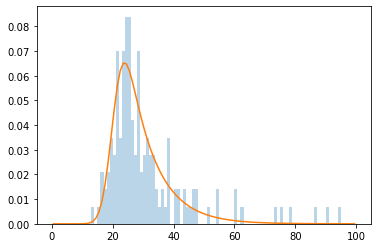

In [78]:
h, edges =np.histogram(IMTs[0]["IMT_t"], bins=range(0,101), density=True)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
out = plt.stairs(h, edges, fill=True, alpha=0.3)
plt.plot(centers, fitted_curve)
mse = mean_squared_error(h, fitted_curve)
aic_1 = aic(h, fitted_curve, 3)

In [79]:
aic_1

-4.145027307366874

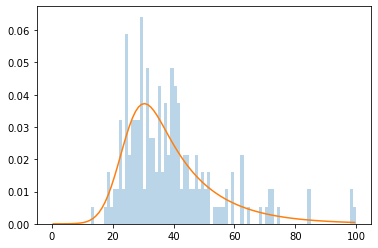

In [8]:
h, edges =np.histogram(IMTs[5]["IMT_t"], bins=range(0,101), density=True)
popt,pcov=(curve_fit(emg_fit_func, centers, h))
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
out = plt.stairs(h, edges, fill=True, alpha=0.3)
plt.plot(centers, fitted_curve)
mse = mean_squared_error(h, fitted_curve)
aic = calculate_aic(len(h), mse, 3)

In [17]:
x = np.array(IMTs[5]["G1_t"])
x = x[~np.isnan(x)]
x = x.reshape(-1,1)
gmm = GaussianMixture(n_components=2, random_state=0).fit(x)

In [18]:
mean = gmm.fit(x).means_  
covs  = gmm.fit(x).covariances_
weights = gmm.fit(x).weights_

y_axis0 = norm.pdf(centers, float(mean[0][0]), np.sqrt(float(covs[0][0][0])))*weights[0] # 1st gaussian
y_axis1 = norm.pdf(centers, float(mean[1][0]), np.sqrt(float(covs[1][0][0])))*weights[1] # 2nd gaussian

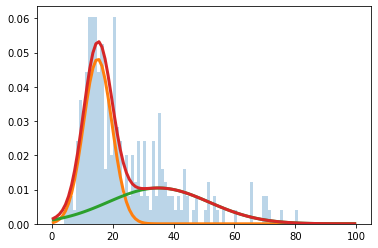

In [19]:
h, edges =np.histogram(IMTs[5]["G1_t"], bins=range(0,101), density=True)
out = plt.stairs(h, edges, fill=True, alpha=0.3)
plt.plot(centers, y_axis0, lw=3)
plt.plot(centers, y_axis1, lw=3)
plt.plot(centers, y_axis0+y_axis1, lw=3)

In [24]:
x = np.array(IMTs[5]["G1_t"])
x = x[~np.isnan(x)]
x = x.reshape(-1,1)
aics = []
min_aic = 0
counter=1
for i in range (10): # test the AIC/BIC metric between 1 and 10 components
    gmm = GaussianMixture(n_components = counter, max_iter=1000, random_state=0, covariance_type = 'full')
    labels = gmm.fit(x).predict(x)
    aic = gmm.aic(x)
    aics.append(aic)
    if aic < min_aic or min_aic == 0:
        min_aic = aic
        opt_aic = counter
    counter += 1

C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [80]:
x = np.array(IMTs[5]["G1_t"])
x = x[~np.isnan(x)]
x = x.reshape(-1,1)

# Fit models with 1-10 components
k_arr = np.arange(10) + 1
models = [GaussianMixture(n_components=k).fit(x) for k in k_arr]


C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [82]:
def plot_mixture(gmm, X, show_legend=True, ax=None):
    if ax is None:
        ax = plt.gca()

 # Compute PDF of whole mixture
    x = np.arange(0.5, 100.5, 1)
    logprob = gmm.score_samples(x.reshape(-1, 1))
    pdf = np.exp(logprob)

 # Compute PDF for each component
    responsibilities = gmm.predict_proba(x.reshape(-1, 1))
    pdf_individual = responsibilities * pdf[:, np.newaxis]
    
 # Calculate mse and aic
    h, edges =np.histogram(X, bins=range(0,101), density=True)
    mse = mean_squared_error(h, pdf)
    aic = calculate_aic(len(h), mse, 3)
    
 # Plot data histogram
    ax.hist(X, bins=range(0,101), density=True, histtype='stepfilled', alpha=0.4, label='Data')

 # Plot PDF of whole model
    ax.plot(x, pdf, '-k', label='Mixture PDF')

 # Plot PDF of each component
    ax.plot(x, pdf_individual, '--', label='Component PDF')
    ax.set_xlabel('$x$')
    ax.set_ylabel('$p(x)$')
    if show_legend:
        ax.legend()
        

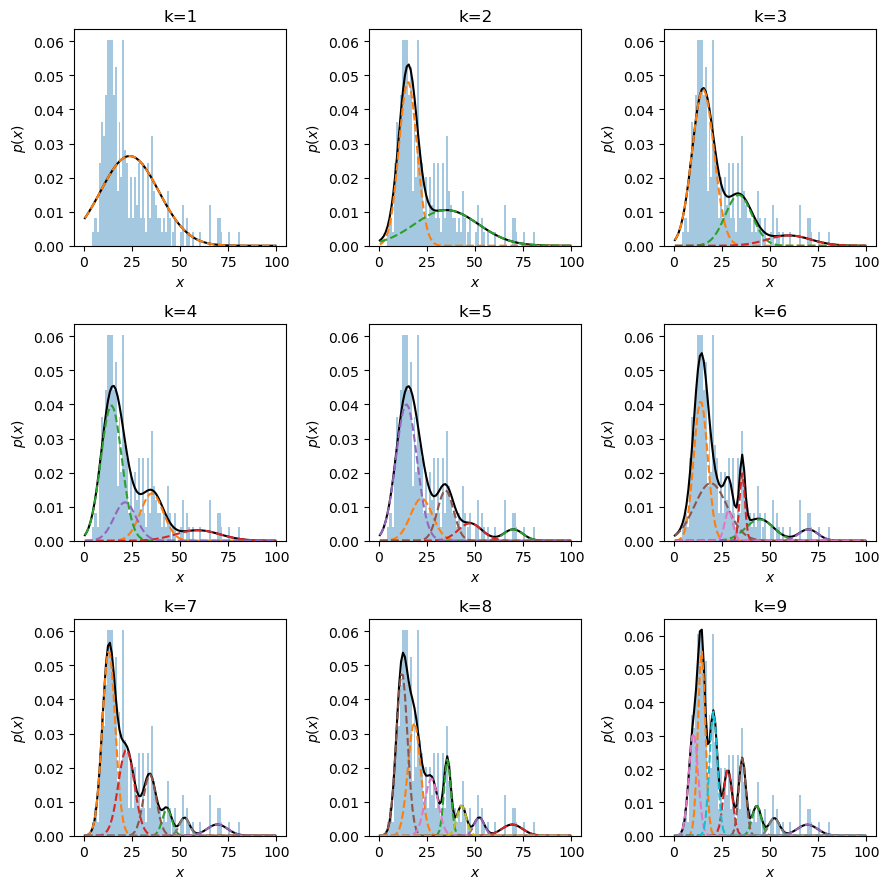

In [83]:
_, axes = plt.subplots(3, 3, figsize=np.array([3,3])*3, dpi=100)
for gmm, ax in zip(models, axes.ravel()):
    plot_mixture(gmm, x, show_legend=False, ax=ax)
    ax.set_title(f'k={gmm.n_components}')
plt.tight_layout()


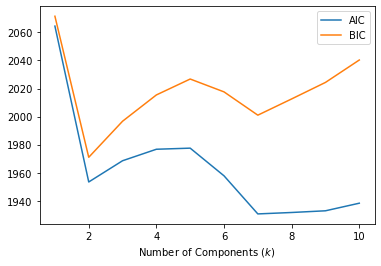

In [84]:
# Compute metrics to determine best hyperparameter
AIC = [m.aic(x) for m in models]
BIC = [m.bic(x) for m in models]
# Plot these metrics
plt.plot(k_arr, AIC, label='AIC')
plt.plot(k_arr, BIC, label='BIC')
plt.xlabel('Number of Components ($k$)')
plt.legend()

C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


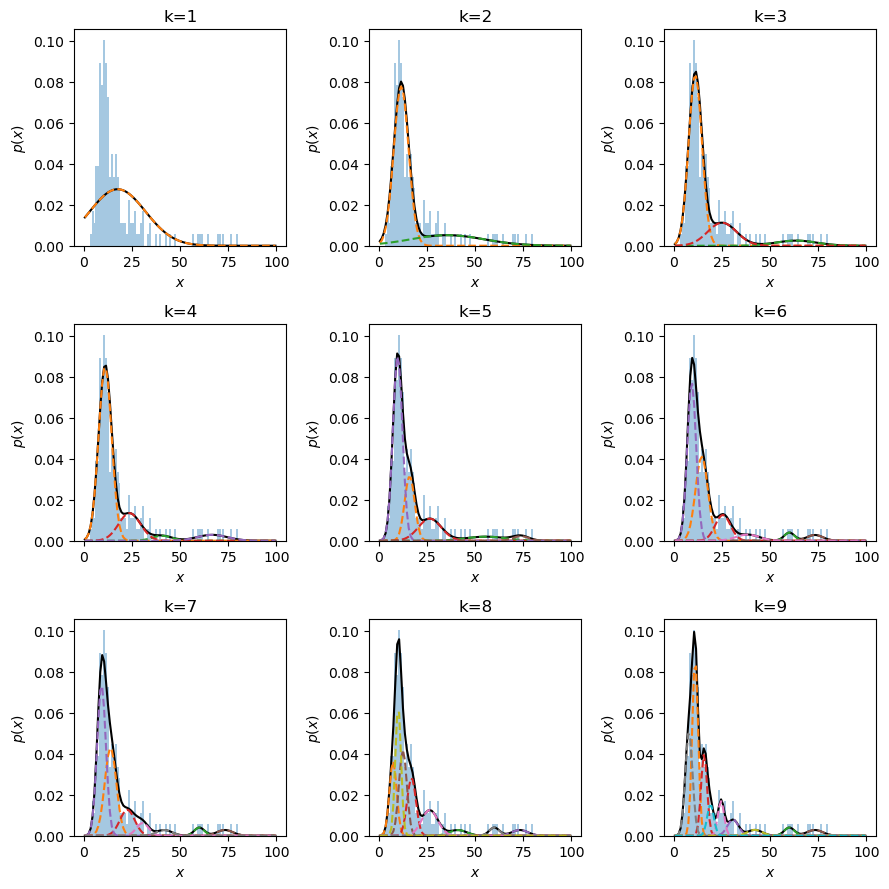

In [89]:
x = np.array(IMTs[0]["G1_t"])
x = x[~np.isnan(x)]
x = x.reshape(-1,1)

# Fit models with 1-10 components
k_arr = np.arange(10) + 1
models = [GaussianMixture(n_components=k).fit(x) for k in k_arr]

_, axes = plt.subplots(3, 3, figsize=np.array([3,3])*3, dpi=100)
for gmm, ax in zip(models, axes.ravel()):
    plot_mixture(gmm, x, show_legend=False, ax=ax)
    ax.set_title(f'k={gmm.n_components}')
plt.tight_layout()

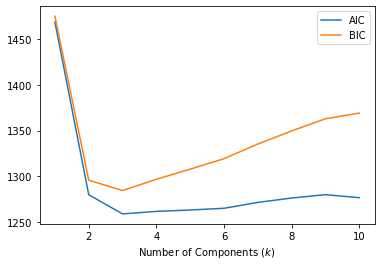

In [90]:
# Compute metrics to determine best hyperparameter
AIC = [m.aic(x) for m in models]
BIC = [m.bic(x) for m in models]
# Plot these metrics
plt.plot(k_arr, AIC, label='AIC')
plt.plot(k_arr, BIC, label='BIC')
plt.xlabel('Number of Components ($k$)')
plt.legend()

C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


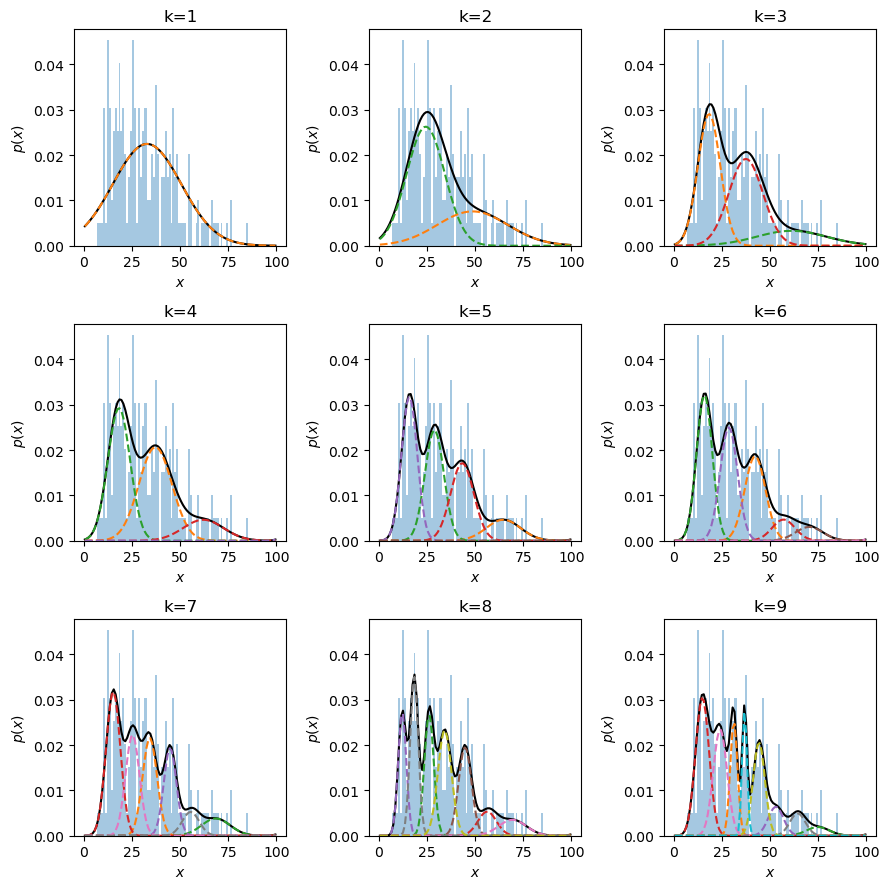

In [91]:
x = np.array(IMTs[1]["G1_t"])
x = x[~np.isnan(x)]
x = x.reshape(-1,1)

# Fit models with 1-10 components
k_arr = np.arange(10) + 1
models = [GaussianMixture(n_components=k).fit(x) for k in k_arr]

_, axes = plt.subplots(3, 3, figsize=np.array([3,3])*3, dpi=100)
for gmm, ax in zip(models, axes.ravel()):
    plot_mixture(gmm, x, show_legend=False, ax=ax)
    ax.set_title(f'k={gmm.n_components}')
plt.tight_layout()

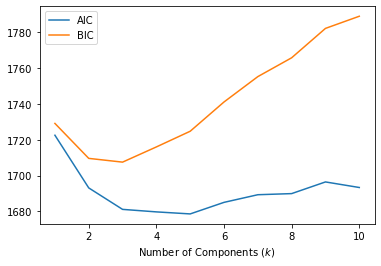

In [92]:
# Compute metrics to determine best hyperparameter
AIC = [m.aic(x) for m in models]
BIC = [m.bic(x) for m in models]
# Plot these metrics
plt.plot(k_arr, AIC, label='AIC')
plt.plot(k_arr, BIC, label='BIC')
plt.xlabel('Number of Components ($k$)')
plt.legend()

C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


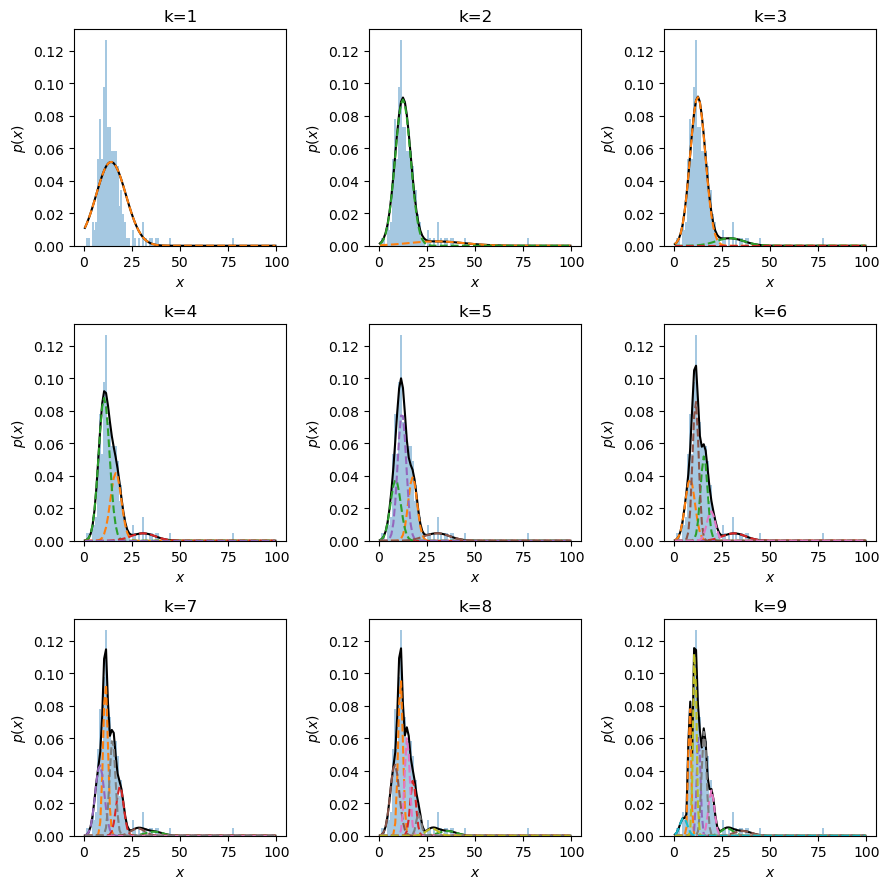

In [93]:
x = np.array(IMTs[4]["G1_t"])
x = x[~np.isnan(x)]
x = x.reshape(-1,1)

# Fit models with 1-10 components
k_arr = np.arange(10) + 1
models = [GaussianMixture(n_components=k).fit(x) for k in k_arr]

_, axes = plt.subplots(3, 3, figsize=np.array([3,3])*3, dpi=100)
for gmm, ax in zip(models, axes.ravel()):
    plot_mixture(gmm, x, show_legend=False, ax=ax)
    ax.set_title(f'k={gmm.n_components}')
plt.tight_layout()

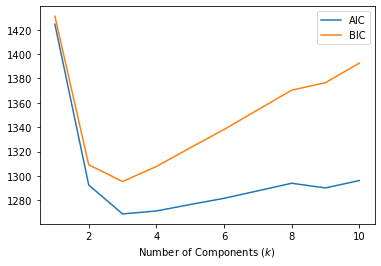

In [94]:
# Compute metrics to determine best hyperparameter
AIC = [m.aic(x) for m in models]
BIC = [m.bic(x) for m in models]
# Plot these metrics
plt.plot(k_arr, AIC, label='AIC')
plt.plot(k_arr, BIC, label='BIC')
plt.xlabel('Number of Components ($k$)')
plt.legend()

C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


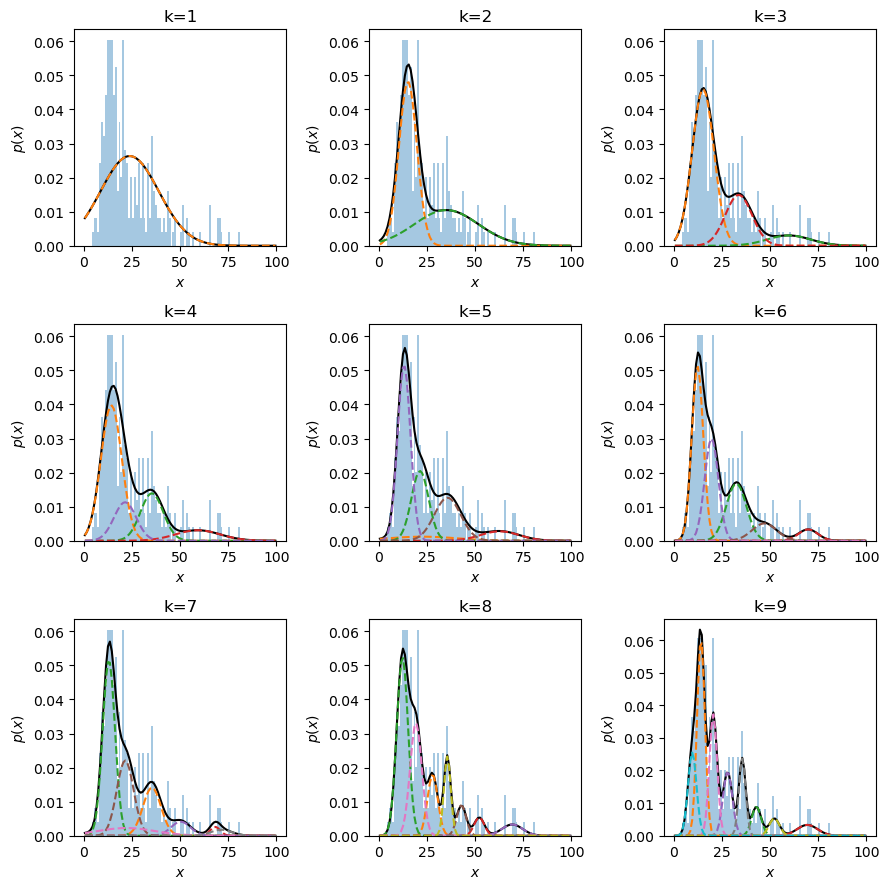

In [95]:
x = np.array(IMTs[5]["G1_t"])
x = x[~np.isnan(x)]
x = x.reshape(-1,1)

# Fit models with 1-10 components
k_arr = np.arange(10) + 1
models = [GaussianMixture(n_components=k).fit(x) for k in k_arr]

_, axes = plt.subplots(3, 3, figsize=np.array([3,3])*3, dpi=100)
for gmm, ax in zip(models, axes.ravel()):
    plot_mixture(gmm, x, show_legend=False, ax=ax)
    ax.set_title(f'k={gmm.n_components}')
plt.tight_layout()

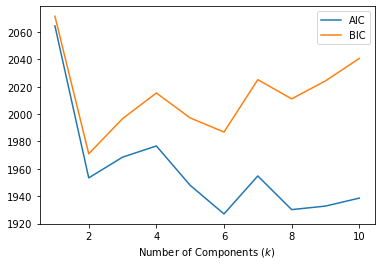

In [96]:
# Compute metrics to determine best hyperparameter
AIC = [m.aic(x) for m in models]
BIC = [m.bic(x) for m in models]
# Plot these metrics
plt.plot(k_arr, AIC, label='AIC')
plt.plot(k_arr, BIC, label='BIC')
plt.xlabel('Number of Components ($k$)')
plt.legend()

C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\sklearn\cluster\_kmeans.py:1036: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


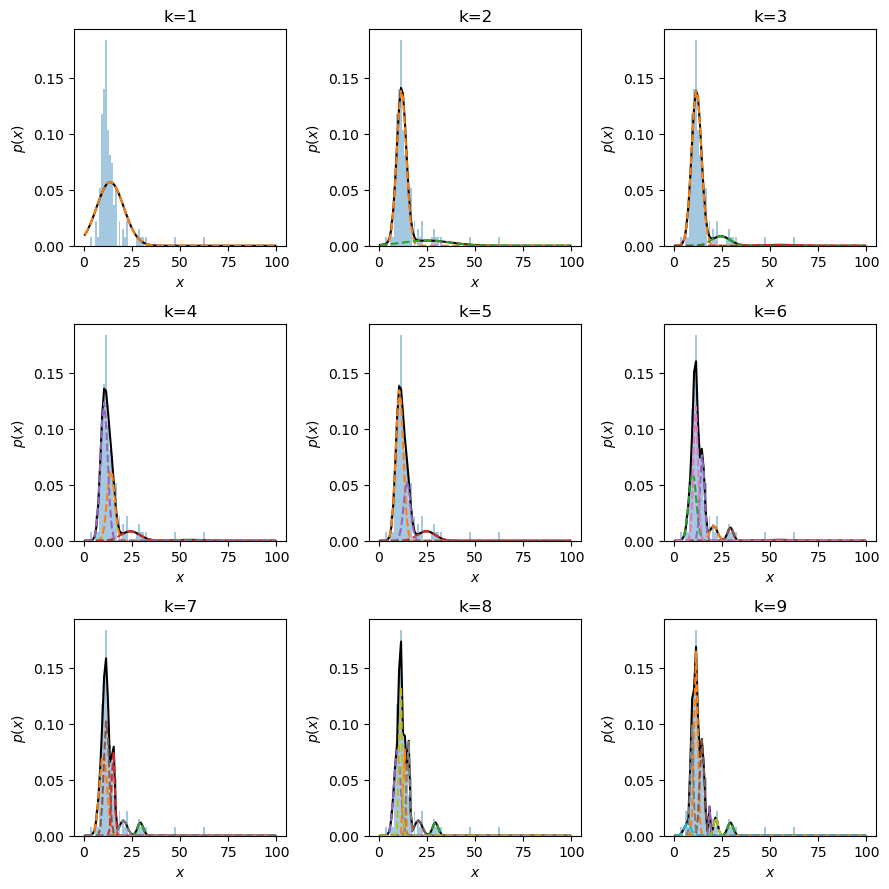

In [98]:
x = np.array(IMTs[6]["G1_t"])
x = x[~np.isnan(x)]
x = x.reshape(-1,1)

# Fit models with 1-10 components
k_arr = np.arange(10) + 1
models = [GaussianMixture(n_components=k).fit(x) for k in k_arr]

_, axes = plt.subplots(3, 3, figsize=np.array([3,3])*3, dpi=100)
for gmm, ax in zip(models, axes.ravel()):
    plot_mixture(gmm, x, show_legend=False, ax=ax)
    ax.set_title(f'k={gmm.n_components}')
plt.tight_layout()

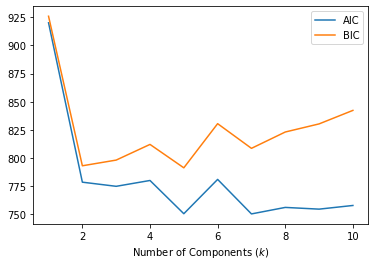

In [99]:
# Compute metrics to determine best hyperparameter
AIC = [m.aic(x) for m in models]
BIC = [m.bic(x) for m in models]
# Plot these metrics
plt.plot(k_arr, AIC, label='AIC')
plt.plot(k_arr, BIC, label='BIC')
plt.xlabel('Number of Components ($k$)')
plt.legend()